# Advanced Linear Regression Analysis

In this notebook, we're taking a deep dive into OLS Linear Regression. It's easy to just call `.fit()` and move on, but to actually understand the data, we need to look at statistical summaries, multicollinearity, and residual diagnostics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Data Loading & Feature Engineering
We'll load the dataset and take a quick look at the feature correlations. If features are highly correlated with each other, we might face multicollinearity issues which inflate standard errors in our OLS model.

In [2]:
data = load_diabetes()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['TARGET'] = data.target

# Let's see the correlation of features with our target
correlations = df.corr()['TARGET'].sort_values(ascending=False)
print("Feature correlations with target:")
print(correlations)

Feature correlations with target:
TARGET    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: TARGET, dtype: float64


## 2. Deep Exploratory Data Analysis (EDA)
Let's plot the top two correlated features against the target to visually confirm the linear relationship.

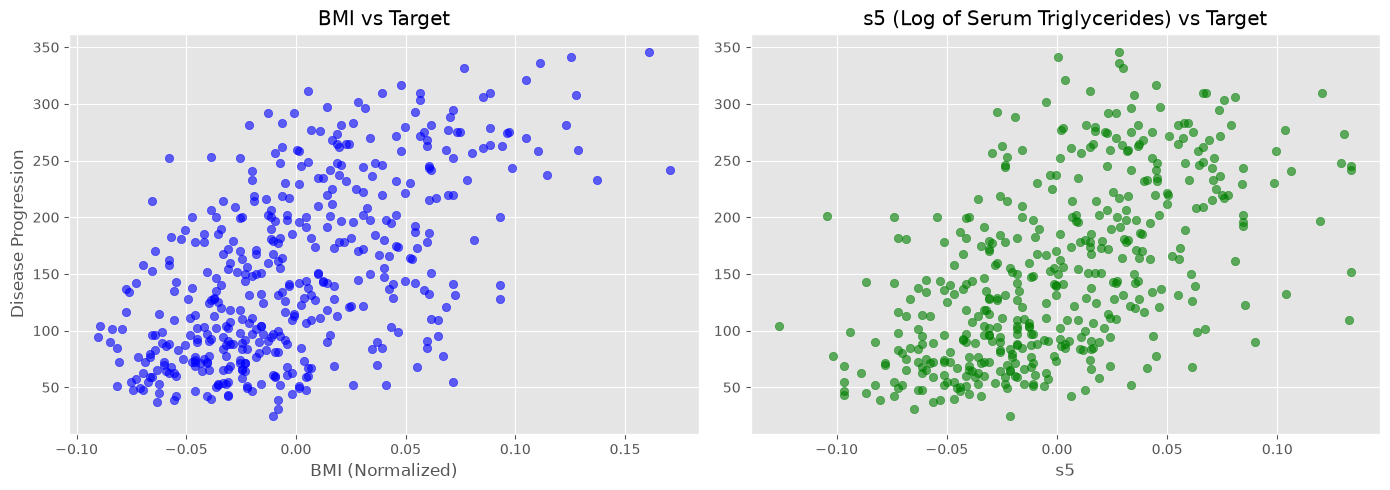

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['bmi'], df['TARGET'], alpha=0.6, color='blue')
axes[0].set_title('BMI vs Target')
axes[0].set_xlabel('BMI (Normalized)')
axes[0].set_ylabel('Disease Progression')

axes[1].scatter(df['s5'], df['TARGET'], alpha=0.6, color='green')
axes[1].set_title('s5 (Log of Serum Triglycerides) vs Target')
axes[1].set_xlabel('s5')

plt.tight_layout()
plt.show()

## 3. Statistical Modeling with OLS
Using `statsmodels` gives us the beautiful summary table. Watch the p-values (P>|t|). Features with a p-value > 0.05 are generally not statistically significant and might be adding noise.

In [4]:
X = df.drop('TARGET', axis=1)
X = sm.add_constant(X)  # intercept is crucial
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ols_model = sm.OLS(y_train, X_train).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 TARGET   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           5.41e-50
Time:                        16:20:14   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

## 4. Advanced Evaluation: Residual Diagnostics
To truly trust a linear model, the residuals (errors) should be randomly distributed. If they form a funnel shape or a curve, our assumption of linearity or constant variance is violated!

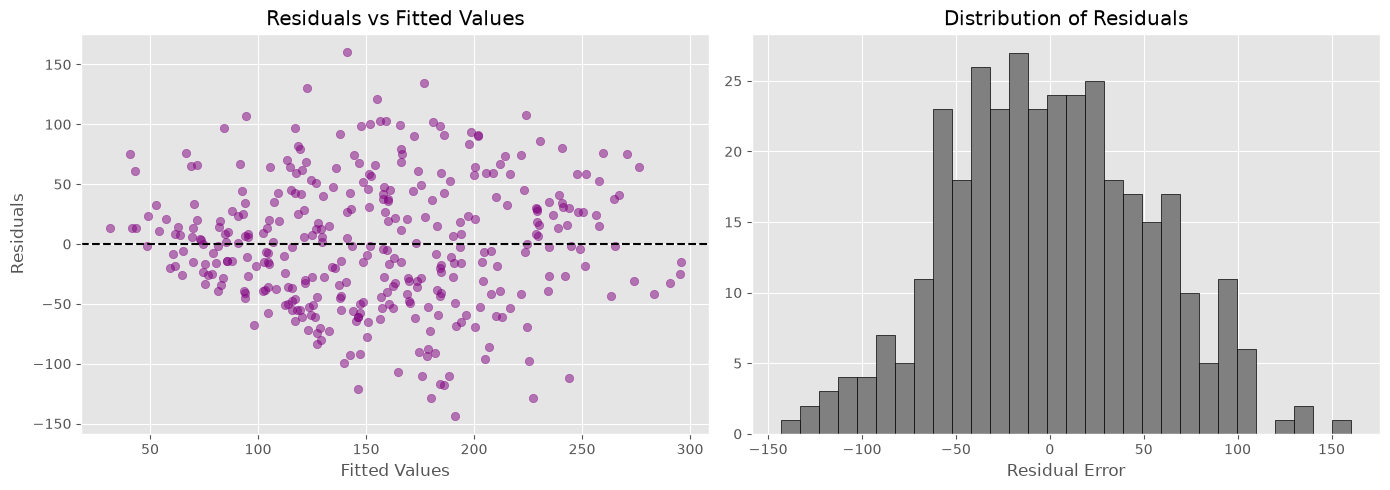

In [5]:
train_preds = ols_model.predict(X_train)
residuals = y_train - train_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted values
axes[0].scatter(train_preds, residuals, alpha=0.5, color='purple')
axes[0].axhline(y=0, color='black', linestyle='--')
axes[0].set_title('Residuals vs Fitted Values')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Histogram of residuals to check normality
axes[1].hist(residuals, bins=30, color='gray', edgecolor='black')
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual Error')

plt.tight_layout()
plt.show()

## 5. Final Test Set Evaluation

In [6]:
test_preds = ols_model.predict(X_test)
rmse = np.sqrt(np.mean((y_test - test_preds)**2))
print(f"Final RMSE on unseen test data: {rmse:.2f}")

Final RMSE on unseen test data: 53.85
